# **EDAV (22ADC32N) – Course-End Project**
# **Title** : **Restaurant Customer Preference Analysis**
**Objective** : To analyze the Titanic Dataset using Numpy and Pandas to study passenger survival rates.To handle missing values and examine the influence of age,gender,passenger class,and embarkation port on survival.To visualize the results using bar plots and heatmaps to identify survival patterns.

In [13]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/restaurant_customer_satisfaction.csv')

print(df.head())
print(df.info())
print(df.shape)

   CustomerID  Age  Gender       Income VisitFrequency  AverageSpend  \
0         718   33    Male  117671.6291        Monthly    179.798439   
1         792   57  Female  105429.5861         Weekly    176.195249   
2         955   56    Male  125265.0948         Rarely    178.713392   
3         965   58  Female  133880.8843        Monthly    176.967930   
4        1056   32  Female  115413.2185         Weekly    194.071246   

  PreferredCuisine TimeOfVisit  GroupSize DiningOccasion  MealType  \
0          Mexican   Breakfast          8    Celebration  Takeaway   
1          Mexican       Lunch          3    Celebration  Takeaway   
2         American   Breakfast          9    Celebration  Takeaway   
3          Italian       Lunch          1       Business   Dine-in   
4          Chinese      Dinner          7       Business   Dine-in   

   OnlineReservation  DeliveryOrder  LoyaltyProgramMember  WaitTime  \
0                  1              1                     1     39.46   
1   

# **Data Cleaning**

In [18]:
print(df.isnull().sum())
print(df.duplicated().sum())

df = df.drop_duplicates()

print("Minimum Age:", df['Age'].min())
print("Maximum Age:", df['Age'].max())
print(df['HighSatisfaction'].value_counts())

CustomerID              0
Age                     0
Gender                  0
Income                  0
VisitFrequency          0
AverageSpend            0
PreferredCuisine        0
TimeOfVisit             0
GroupSize               0
DiningOccasion          0
MealType                0
OnlineReservation       0
DeliveryOrder           0
LoyaltyProgramMember    0
WaitTime                0
ServiceRating           0
FoodRating              0
AmbianceRating          0
HighSatisfaction        0
dtype: int64
0
Minimum Age: 18
Maximum Age: 69
HighSatisfaction
0    1053
1     447
Name: count, dtype: int64


# **Q1. Calculate average, minimum, and maximum age using NumPy**

In [19]:
age_data = df.dropna(subset=['Age'])

age = age_data['Age'].to_numpy()
satisfaction = age_data['HighSatisfaction'].to_numpy()

satisfied_age = age[satisfaction == 1]

print("Highly Satisfied Customers:")
print("Average Age:", np.mean(satisfied_age))
print("Minimum Age:", np.min(satisfied_age))
print("Maximum Age:", np.max(satisfied_age))

not_satisfied_age = age[satisfaction == 0]

print("\nCustomers Not Highly Satisfied:")
print("Average Age:", np.mean(not_satisfied_age))
print("Minimum Age:", np.min(not_satisfied_age))
print("Maximum Age:", np.max(not_satisfied_age))

Highly Satisfied Customers:
Average Age: 44.12751677852349
Minimum Age: 18
Maximum Age: 69

Customers Not Highly Satisfied:
Average Age: 43.706552706552706
Minimum Age: 18
Maximum Age: 69


# **Q2. Analyze survival probability based on passenger class and gender**

In [20]:
gender_satisfaction = df.groupby('Gender')['HighSatisfaction'].mean()
print("Satisfaction Rate by Gender:")
print(gender_satisfaction)

loyalty_satisfaction = df.groupby('LoyaltyProgramMember')['HighSatisfaction'].mean()
print("\nSatisfaction Rate by Loyalty Membership:")
print(loyalty_satisfaction)

gender_loyalty = df.groupby(['Gender', 'LoyaltyProgramMember'])['HighSatisfaction'].mean()
print("\nSatisfaction Rate by Gender and Loyalty Membership:")
print(gender_loyalty)

Satisfaction Rate by Gender:
Gender
Female    0.300395
Male      0.295547
Name: HighSatisfaction, dtype: float64

Satisfaction Rate by Loyalty Membership:
LoyaltyProgramMember
0    0.264103
1    0.334722
Name: HighSatisfaction, dtype: float64

Satisfaction Rate by Gender and Loyalty Membership:
Gender  LoyaltyProgramMember
Female  0                       0.285360
        1                       0.317416
Male    0                       0.241379
        1                       0.351648
Name: HighSatisfaction, dtype: float64


# **Q3. Handle missing values in Age and Cabin**

In [21]:
print("Missing Values Before Imputation:")
print(df.isnull().sum())

df['Age'] = df['Age'].fillna(df['Age'].median())

numerical_columns = [
    'Income', 'AverageSpend', 'GroupSize', 'WaitTime',
    'ServiceRating', 'FoodRating', 'AmbianceRating'
]

for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

categorical_columns = [
    'Gender', 'VisitFrequency', 'PreferredCuisine',
    'TimeOfVisit', 'DiningOccasion', 'MealType',
    'OnlineReservation', 'DeliveryOrder', 'LoyaltyProgramMember'
]

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing Values After Imputation:")
print(df.isnull().sum())

Missing Values Before Imputation:
CustomerID              0
Age                     0
Gender                  0
Income                  0
VisitFrequency          0
AverageSpend            0
PreferredCuisine        0
TimeOfVisit             0
GroupSize               0
DiningOccasion          0
MealType                0
OnlineReservation       0
DeliveryOrder           0
LoyaltyProgramMember    0
WaitTime                0
ServiceRating           0
FoodRating              0
AmbianceRating          0
HighSatisfaction        0
dtype: int64

Missing Values After Imputation:
CustomerID              0
Age                     0
Gender                  0
Income                  0
VisitFrequency          0
AverageSpend            0
PreferredCuisine        0
TimeOfVisit             0
GroupSize               0
DiningOccasion          0
MealType                0
OnlineReservation       0
DeliveryOrder           0
LoyaltyProgramMember    0
WaitTime                0
ServiceRating           0
FoodRatin

# **Q4. Group passengers by embarkation port and survival**

In [22]:
occasion_stats = df.groupby(
    ['DiningOccasion', 'HighSatisfaction']
).agg(
    Customer_Count=('HighSatisfaction', 'count'),
    Average_Age=('Age', 'mean'),
    Average_Spend=('AverageSpend', 'mean')
)

print("Descriptive Statistics:")
print(occasion_stats)

occasion_satisfaction = df.groupby('DiningOccasion')['HighSatisfaction'].mean()
print("\nSatisfaction Rate by Dining Occasion:")
print(occasion_satisfaction)

occasion_count = df.groupby('DiningOccasion')['HighSatisfaction'].count()
print("\nCustomer Count by Dining Occasion:")
print(occasion_count)

Descriptive Statistics:
                                 Customer_Count  Average_Age  Average_Spend
DiningOccasion HighSatisfaction                                            
Business       0                            361    43.828255     133.204530
               1                            139    44.122302     131.037274
Casual         0                            334    43.254491     130.886015
               1                            147    43.986395     125.147768
Celebration    0                            358    44.005587     130.342576
               1                            161    44.260870     134.172873

Satisfaction Rate by Dining Occasion:
DiningOccasion
Business       0.278000
Casual         0.305613
Celebration    0.310212
Name: HighSatisfaction, dtype: float64

Customer Count by Dining Occasion:
DiningOccasion
Business       500
Casual         481
Celebration    519
Name: HighSatisfaction, dtype: int64


# **Bar plot – Survival rate by passenger class**

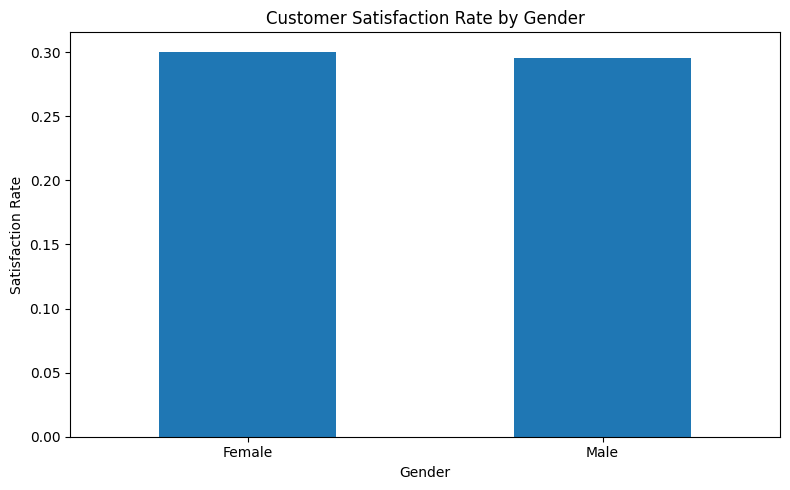

In [23]:
gender_satisfaction = df.groupby('Gender')['HighSatisfaction'].mean()

plt.figure(figsize=(8, 5))
gender_satisfaction.plot(kind='bar')

plt.title('Customer Satisfaction Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Satisfaction Rate')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# **Bar plot – Survival rate by gender**




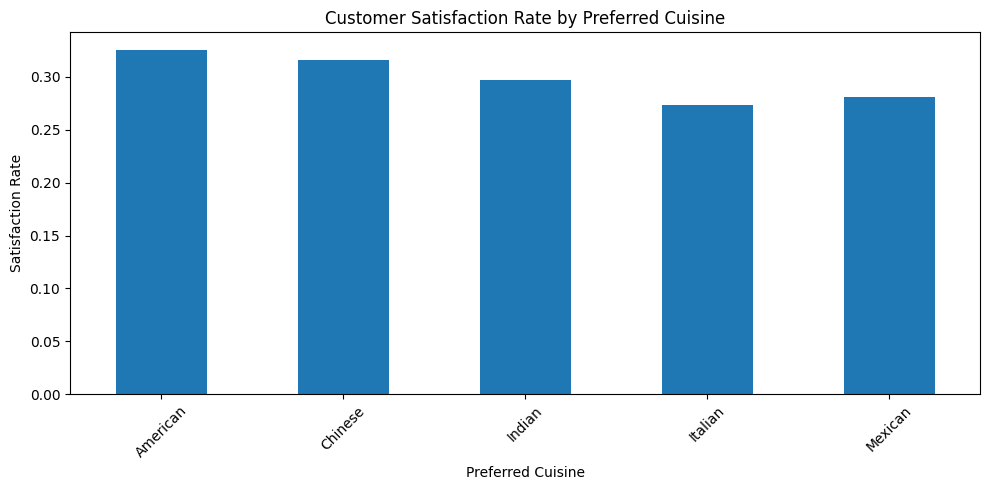

In [24]:
cuisine_satisfaction = df.groupby('PreferredCuisine')['HighSatisfaction'].mean()

plt.figure(figsize=(10, 5))
cuisine_satisfaction.plot(kind='bar')

plt.title('Customer Satisfaction Rate by Preferred Cuisine')
plt.xlabel('Preferred Cuisine')
plt.ylabel('Satisfaction Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **Bar plot – Survival rate by class and gender**

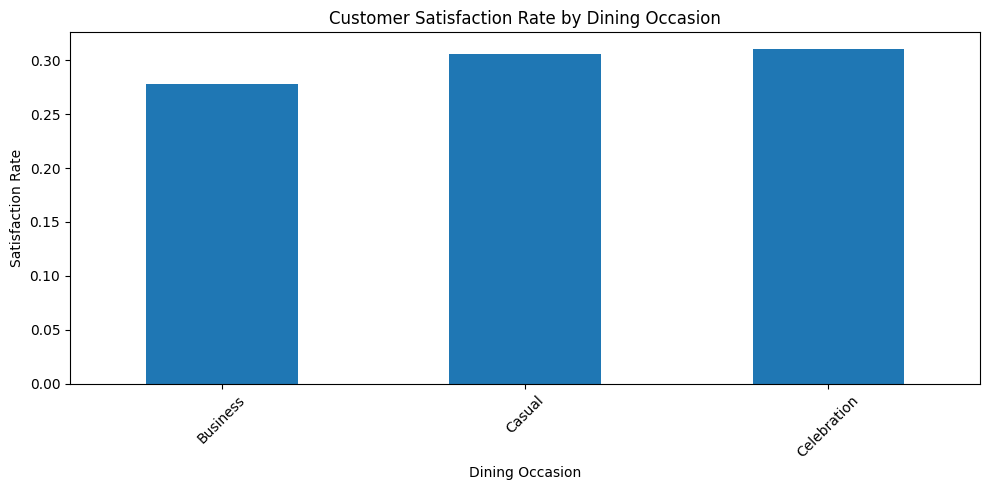

In [25]:
occasion_satisfaction = df.groupby('DiningOccasion')['HighSatisfaction'].mean()

plt.figure(figsize=(10, 5))
occasion_satisfaction.plot(kind='bar')

plt.title('Customer Satisfaction Rate by Dining Occasion')
plt.xlabel('Dining Occasion')
plt.ylabel('Satisfaction Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **Heatmap – Survival counts by embarkation port**

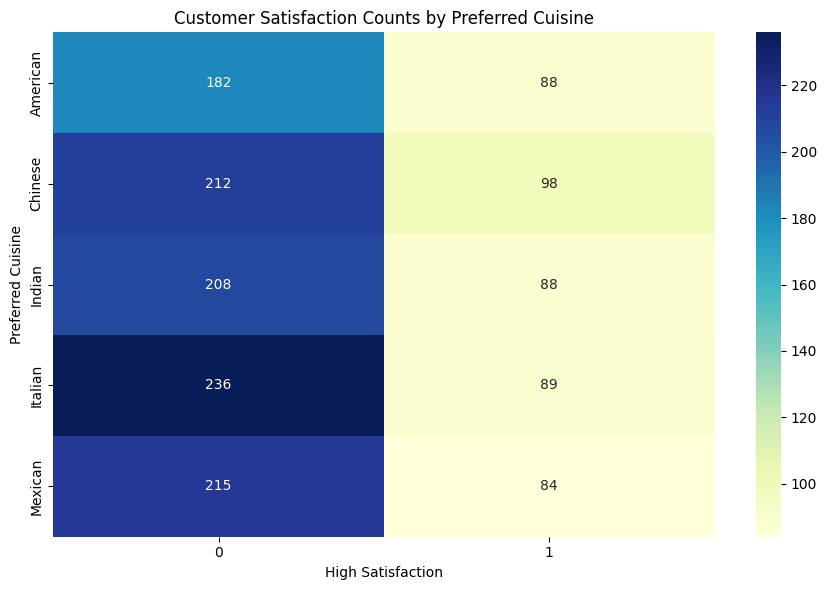

In [26]:
satisfaction_counts = pd.crosstab(
    df['PreferredCuisine'],
    df['HighSatisfaction']
)

plt.figure(figsize=(9, 6))
sns.heatmap(satisfaction_counts, annot=True, fmt='d', cmap='YlGnBu')

plt.title('Customer Satisfaction Counts by Preferred Cuisine')
plt.xlabel('High Satisfaction')
plt.ylabel('Preferred Cuisine')
plt.tight_layout()
plt.show()

# **Heatmap – Survival rate by class and gender**

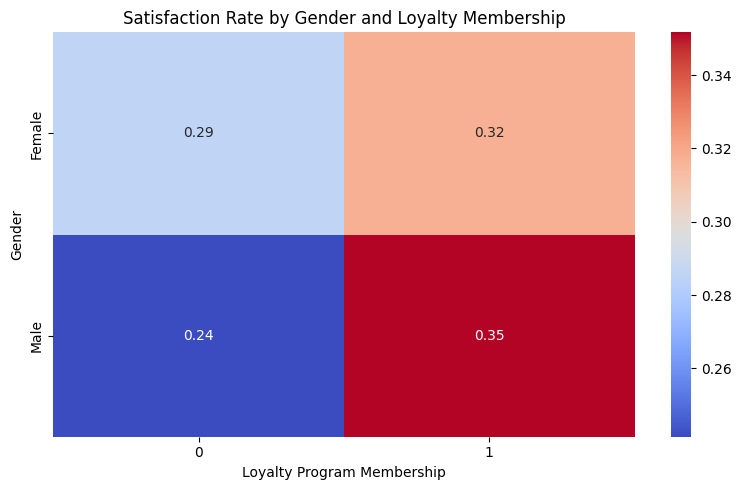

In [27]:
satisfaction_rate = df.pivot_table(
    values='HighSatisfaction',
    index='Gender',
    columns='LoyaltyProgramMember',
    aggfunc='mean'
)

plt.figure(figsize=(8, 5))
sns.heatmap(satisfaction_rate, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Satisfaction Rate by Gender and Loyalty Membership')
plt.xlabel('Loyalty Program Membership')
plt.ylabel('Gender')
plt.tight_layout()
plt.show()